# Portfolio analysis of 10 NSE large caps (Nov-2021 to Oct-2026)

This notebook measures return, risk, beta and risk-adjusted performance for ten large Indian stocks, builds long-only mean-variance portfolios, plots the efficient frontier, and then tests whether the "optimal" weights still work on data they were not fitted on.

- **Universe:** Reliance Industries, HDFC Bank, ICICI Bank, Infosys, Bharti Airtel, ITC, Larsen & Toubro, Sun Pharmaceutical, Maruti Suzuki and Titan Company. Benchmark: NIFTY 50 (`^NSEI`).
- **Data:** daily prices from Yahoo Finance via `yfinance`, saved in `data/raw/` by `src/fetch_data.py`. This notebook runs offline from those files. Untouched copies of the downloads, plus the exchange circulars, company filings and news pages behind the corporate-action corrections and the risk-free rate, are in `source_data/` (index: `source_data/README.md`).
- **Window:** 1-Nov-2021 to 30-Oct-2026 (five years).
- **Risk-free rate:** 5.93% a year, the 91-day T-bill cut-off yield at the RBI auction of 28-Oct-2026 ([Economic Times, 28-Oct-2026](https://economictimes.indiatimes.com/markets/bonds/rbi-accepts-20-bps-higher-treasury-bill-cutoff-yields-than-last-auction/articleshow/135284706.cms)), held constant.
- **Code:** the calculations live in `src/` (`data_cleaning.py`, `portfolio.py`, `analysis.py`, `plotting.py`). `python src/run_all.py` regenerates the same figures and CSV files; section 11 checks that both give identical numbers.

Educational project, not investment advice.

In [1]:
%matplotlib inline
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import plotting
from src import portfolio as pf
from src.analysis import (PORTFOLIO_NAMES, estimate_inputs, optimise_set, out_of_sample, run_analysis,
                          summarise_portfolios)
from src.config import (ANALYSIS_END, ANALYSIS_START, BENCHMARK, DATA_DIR, FIG_DIR, IS_END, N_FRONTIER,
                        N_FRONTIER_LOWER, N_MONTE_CARLO, OOS_START, RF_ANNUAL, RF_ARITH, RF_DAILY, RF_WEEKLY,
                        SECTORS, SEED, STOCK_LABELS, TRADING_DAYS, WEIGHT_CAP)
from src.data_cleaning import clean_prices, load_raw, panel

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)


def fmt(df, pct=(), dec=(), dec3=(), dec5=()):
    # Format selected columns as text for display (percent, 2, 3 or 5 decimals).
    out = df.copy()
    for cols, f in ((pct, "{:.1%}"), (dec, "{:.2f}"), (dec3, "{:.3f}"), (dec5, "{:.5f}")):
        for c in cols:
            out[c] = out[c].map(lambda v, f=f: "" if pd.isna(v) else f.format(v))
    return out


print(f"Risk-free rate {RF_ANNUAL:.2%} a year -> daily {RF_DAILY:.5%} -> {RF_ARITH:.2%} a year on the "
      f"arithmetic x{TRADING_DAYS} basis used for mean returns")

Risk-free rate 5.93% a year -> daily 0.02286% -> 5.76% a year on the arithmetic x252 basis used for mean returns


## 1. Data

`src/fetch_data.py` stores one raw CSV per ticker (Open, High, Low, Close, Adj Close, Volume, Dividends, Stock Splits) and a metadata file. Downloads start on 1-Oct-2021 so that the first return of the window has a previous close. `Adj Close` is Yahoo's price adjusted for splits, bonus issues and cash dividends, so its daily change is a total return. `^NSEI` is the NIFTY 50 **price** index: it leaves out dividends (sized in section 4). `NIFTYBEES` (an ETF on the NIFTY 50) is downloaded only for that comparison.

In [2]:
meta = json.loads((DATA_DIR / "metadata.json").read_text(encoding="utf-8"))
print("Source:", meta["source"], "| yfinance", meta["yfinance_version"], "| downloaded", meta["download_timestamp_ist"])
universe = pd.DataFrame([
    {"ticker": t, "label": v["label"], "name": v["name"], "sector": SECTORS.get(v["label"], "Index / ETF"),
     "rows": meta["summary"][t]["rows"], "first date": meta["summary"][t]["first_date"],
     "last date": meta["summary"][t]["last_date"], "last close (Rs)": meta["summary"][t]["last_close"]}
    for t, v in meta["tickers"].items()]).set_index("ticker")
display(universe)

Source: Yahoo Finance, downloaded with the yfinance Python package | yfinance 1.7.0 | downloaded 2026-10-31 23:34:47 IST


,label,name,sector,rows,first date,last date,last close (Rs)
ticker,,,,,,,
RELIANCE.NS,RELIANCE,Reliance Industries,Energy / conglomerate,1256,2021-10-01,2026-10-30,1164.90
HDFCBANK.NS,HDFCBANK,HDFC Bank,Private bank,1256,2021-10-01,2026-10-30,692.80
ICICIBANK.NS,ICICIBANK,ICICI Bank,Private bank,1256,2021-10-01,2026-10-30,1398.00
INFY.NS,INFY,Infosys,IT services,1256,2021-10-01,2026-10-30,1185.00
BHARTIARTL.NS,BHARTIARTL,Bharti Airtel,Telecom,1256,2021-10-01,2026-10-30,1973.70
ITC.NS,ITC,ITC,FMCG / tobacco,1256,2021-10-01,2026-10-30,265.60
LT.NS,LT,Larsen & Toubro,Engineering & construction,1256,2021-10-01,2026-10-30,3871.70
SUNPHARMA.NS,SUNPHARMA,Sun Pharmaceutical,Pharma,1256,2021-10-01,2026-10-30,1777.70
MARUTI.NS,MARUTI,Maruti Suzuki,Automobiles,1256,2021-10-01,2026-10-30,11397.00


## 2. Data hygiene

`clean_prices()` in `src/data_cleaning.py` runs six steps and logs each one:

1. count missing values per series;
2. treat stock rows with zero traded volume as missing, because the vendor carried the previous price forward;
3. keep only days on which all 11 series (10 stocks and NIFTY) have a real price;
4. correct the two demergers (Reliance / Jio Financial Services and ITC / ITC Hotels);
5. review every one-day return below -8% against news and corporate actions;
6. confirm that bonus issues leave no artificial jump.

In [3]:
clean = clean_prices()
print("\n".join(clean.log))

DATA HYGIENE REPORT

1) Missing values in the raw union of dates:
   RELIANCE    rows= 1256 missing= 0 
   HDFCBANK    rows= 1256 missing= 0 
   ICICIBANK   rows= 1256 missing= 0 
   INFY        rows= 1256 missing= 0 
   BHARTIARTL  rows= 1256 missing= 0 
   ITC         rows= 1256 missing= 0 
   LT          rows= 1256 missing= 0 
   SUNPHARMA   rows= 1256 missing= 0 
   MARUTI      rows= 1256 missing= 0 
   TITAN       rows= 1256 missing= 0 
   NIFTY50     rows= 1255 missing= 1 2026-01-15
   NIFTYBEES   rows= 1255 missing= 1 2025-10-24

2) Zero-volume stock rows (stale prices, treated as missing):
   2025-03-18  9 stocks: RELIANCE, HDFCBANK, ICICIBANK, INFY, BHARTIARTL, LT, SUNPHARMA, MARUTI, TITAN
   2026-01-15 10 stocks: RELIANCE, HDFCBANK, ICICIBANK, INFY, BHARTIARTL, ITC, LT, SUNPHARMA, MARUTI, TITAN

3) Dates dropped when aligning on common trading days:
   2025-03-18: zero volume (stale price) for 9 stocks
   2026-01-15: no price for NIFTY50; zero volume (stale price) for 10 stoc

### 2.1 Missing and stale rows

Two dates are removed when the series are aligned:

- **15-Jan-2026.** NIFTY has no value and every stock shows zero volume. The exchanges were shut for the Maharashtra municipal elections ([Livemint, 15-Jan-2026](https://www.livemint.com/market/stock-market-news/stock-market-holiday-bse-nse-to-remain-shut-for-maharashtra-municipal-elections-commodity-trading-to-begin-at-5-pm-11768439343202.html)), so Yahoo's stock rows are copies of 14-Jan.
- **18-Mar-2025.** Nine of the ten stocks show zero volume and an unchanged price, while NIFTY rose 1.45% and ITC traded normally. This is a gap in the vendor's data, not a holiday. Keeping the row would pair a 0% stock return with a +1.45% market day and push the catch-up into 19-Mar, which distorts daily beta. Dropping the date makes the 19-Mar return cover two sessions for every series alike.

NIFTYBEES also misses 24-Oct-2025; it is forward-filled because only its end-to-end growth is used.

In [4]:
labels = STOCK_LABELS + [BENCHMARK]
raw = load_raw()
adj_raw, vol_raw = panel(raw, "Adj Close", labels), panel(raw, "Volume", labels)
ret_raw = adj_raw / adj_raw.shift(1) - 1
around = slice("2025-03-17", "2025-03-19")
check_day = pd.DataFrame({
    "NIFTY return": ret_raw.loc[around, BENCHMARK],
    "stocks with zero volume": (vol_raw.loc[around, STOCK_LABELS] == 0).sum(axis=1),
    "median stock return": ret_raw.loc[around, STOCK_LABELS].median(axis=1),
    "ITC return": ret_raw.loc[around, "ITC"]})
display(fmt(check_day, pct=["NIFTY return", "median stock return", "ITC return"]))
display(clean.dropped_dates)
print(f"Aligned panel: {len(clean.prices)} trading days, {clean.prices.index[0].date()} to {clean.prices.index[-1].date()}")

,NIFTY return,stocks with zero volume,median stock return,ITC return
Date,,,,
2025-03-17,0.5%,0,0.3%,-1.0%
2025-03-18,1.4%,9,0.0%,0.3%
2025-03-19,0.3%,0,1.2%,-1.5%


,date,reason,note
0,2025-03-18,zero volume (stale price) for 9 stocks,
1,2026-01-15,no price for NIFTY50; zero volume (stale price) for 10 stocks,"Exchange holiday for Maharashtra municipal elections - Livemint, 15-Jan-2026..."


Aligned panel: 1254 trading days, 2021-10-01 to 2026-10-30


### 2.2 Demergers

In a demerger part of the parent's value moves into a new listed company. The parent's price falls on the ex-date, but holders lose nothing because they receive the new shares, so an adjusted price series must remove that fall.

I expected Yahoo not to adjust for demergers at all. The data shows that it does, but with factors that differ from the exchanges' price discovery. Comparing Yahoo's close on the day before each ex-date with the exchange close reported in the press gives the factor already inside Yahoo's prices:

| | Reliance / Jio Financial Services | ITC / ITC Hotels |
|---|---|---|
| Ex-date (special pre-open session) | 20-Jul-2023 | 6-Jan-2025 |
| Entitlement | 1 JFSL share per RIL share | 1 ITC Hotels share per 10 ITC shares |
| Exchange close on the previous day | Rs 2,841.85 | Rs 481.60 |
| Parent price set in the special session | Rs 2,580.00 | Rs 455.60 (NSE) |
| Exchange factor = discovered price / previous close | 0.90786 | 0.94601 |
| Factor already embedded in Yahoo's prices | 0.92300 | 0.96292 |

Sources: [Reuters via Yahoo Finance, 20-Jul-2023](https://sg.finance.yahoo.com/news/reliance-starts-special-trading-session-034517252.html); [Indian Express, 20-Jul-2023](https://indianexpress.com/article/business/companies/jio-financial-services-ltd-to-demerge-from-ril-today-8849165/); [Times Now, 6-Jan-2025](https://www.timesnownews.com/business-economy/markets/itc-hotels-share-price-special-trading-session-ends-itc-share-price-adjusts-by-rs-26-on-nse-article-116981147).

Yahoo's factors value a JFSL share at Rs 218.82 instead of the Rs 261.85 set by the exchange, and an ITC Hotels share at Rs 178.60 instead of Rs 260. I use the exchange factor because NSE carried each spun-off company inside the NIFTY 50 as a temporary extra constituent at the discovered price (Times Now, 6-Jan-2025, above), so the benchmark treats the ex-date as value-neutral at that price and the stock series should too. Every Adj Close before the ex-date is multiplied by the residual factor (exchange factor / Yahoo factor): 0.98360 for Reliance and 0.98245 for ITC. The corrected ex-date return is $P_{ex} / (f \times P_{cum}) - 1$: the return of a holder who sold the new shares at the discovered price and reinvested in the parent.

In [5]:
d = clean.demergers.set_index("ticker")
cols = ["ex_date", "spun_off", "prev_close_rs", "discovered_price_rs", "factor_exchange", "factor_yahoo_embedded",
        "factor_applied", "child_value_per_child_share_exchange_rs", "child_value_per_child_share_yahoo_rs",
        "ex_date_return_traded_price", "ex_date_return_as_downloaded", "ex_date_return_corrected"]
display(fmt(d[cols], pct=cols[-3:], dec5=["factor_exchange", "factor_yahoo_embedded", "factor_applied"]).T)

# Effect on the five-year numbers
r_before, base0 = pf.window_returns(clean.prices_as_downloaded, ANALYSIS_START, ANALYSIS_END)
r_after, _ = pf.window_returns(clean.prices, ANALYSIS_START, ANALYSIS_END)
effect = pd.DataFrame({
    "CAGR as downloaded": [pf.cagr(r_before[t], base0) for t in ["RELIANCE", "ITC"]],
    "CAGR corrected": [pf.cagr(r_after[t], base0) for t in ["RELIANCE", "ITC"]]}, index=["RELIANCE", "ITC"])
display(fmt(effect, pct=effect.columns))
assert (d["ex_date_return_corrected"].abs() < 0.08).all()

ticker,RELIANCE,ITC
ex_date,2023-07-20,2025-01-06
spun_off,Jio Financial Services (JFSL),ITC Hotels
prev_close_rs,2841.85,481.6
discovered_price_rs,2580.0,455.6
factor_exchange,0.90786,0.94601
factor_yahoo_embedded,0.92300,0.96292
factor_applied,0.98360,0.98245
child_value_per_child_share_exchange_rs,261.85,260.0
child_value_per_child_share_yahoo_rs,218.82,178.6
ex_date_return_traded_price,-7.8%,-8.1%


,CAGR as downloaded,CAGR corrected
RELIANCE,0.3%,0.6%
ITC,8.6%,9.0%


### 2.3 Large one-day moves

Five one-day returns below -8% remain after the correction. None falls on a dividend, split or demerger date, and each matches a reported news event, so they are real price moves and stay in the data. Two gains above +8% are listed as well. A -8% screen on Yahoo's series would not have caught either demerger: Yahoo's partial adjustment leaves ex-date moves of only -0.1% (Reliance) and -4.5% (ITC). That is why the known demergers are handled explicitly rather than through the screen.

In [6]:
moves = pd.concat([clean.large_moves, clean.large_gains], ignore_index=True)
display(fmt(moves[["date", "ticker", "return", "nifty_return", "yahoo_corporate_action_that_day", "status", "cause",
                   "source"]], pct=["return", "nifty_return"]))
assert not (clean.large_moves["status"] == "UNREVIEWED").any()

,date,ticker,return,nifty_return,yahoo_corporate_action_that_day,status,cause,source
0,2023-04-17,INFY,-9.4%,-0.7%,none,reviewed: genuine price move,Q4 FY23 results below estimates and weak FY24 guidance (4-7%),"The Hindu, 17-Apr-2023 - https://www.thehindu.com/business/infosys-shares-fa..."
1,2023-07-21,INFY,-8.1%,-1.2%,none,reviewed: genuine price move,FY24 revenue growth guidance cut to 1-3.5%,"Reuters via Yahoo Finance, 21-Jul-2023 - https://finance.yahoo.com/news/indi..."
2,2024-01-17,HDFCBANK,-8.4%,-2.1%,none,reviewed: genuine price move,"Q3 FY24 results disappointed (margins, deposit growth)","Economic Times, 19-Mar-2026 - https://economictimes.indiatimes.com/markets/s..."
3,2024-06-04,LT,-12.7%,-5.9%,none,reviewed: genuine price move,General election results day; NIFTY fell 5.93%,"The Hindu, 4-Jun-2024 - https://www.thehindu.com/business/markets/sensex-plu..."
4,2026-01-01,ITC,-9.7%,0.1%,none,reviewed: genuine price move,New excise duty on cigarettes notified on 31-Dec-2025,"Reuters via Yahoo Finance, 1-Jan-2026 - https://sg.finance.yahoo.com/news/in..."
5,2022-04-04,HDFCBANK,10.0%,2.2%,none,reviewed: genuine price move,Merger with HDFC Ltd announced,"CNBC-TV18, 4-Apr-2022 - https://www.cnbctv18.com/market/stocks/hdfc-hdfc-ban..."
6,2025-08-18,MARUTI,8.8%,1.0%,none,reviewed: genuine price move,Proposed GST cut on small cars (28% to 18%),"CNBC-TV18, 18-Aug-2025 - https://www.cnbctv18.com/market/maruti-suzuki-india..."


### 2.4 Bonus issues

Yahoo records both 1:1 bonus issues as 2-for-1 splits and halves the earlier prices. Without that adjustment the ex-date return would be about -50%. In the adjusted series the move is small on both dates, so no artificial jump remains.

In [7]:
display(fmt(clean.splits, pct=["return_if_unadjusted", "adj_close_return", "max_abs_return_t-1_to_t+1"]))
for name, ok in clean.checks.items():
    print(f"[{'PASS' if ok else 'FAIL'}] {name}")
assert all(clean.checks.values())

,ticker,ex_date,ratio,return_if_unadjusted,adj_close_return,max_abs_return_t-1_to_t+1,no_artificial_jump,source
0,RELIANCE,2024-10-28,2:1 (1:1 bonus),-49.8%,0.5%,0.9%,True,"1:1 bonus, record date 28-Oct-2024 - Business Today, 16-Oct-2024 - https://w..."
1,HDFCBANK,2025-08-26,2:1 (1:1 bonus),-50.4%,-0.9%,1.6%,True,"1:1 bonus, ex-date 26-Aug-2025 (record date 27-Aug-2025) - Livemint, 26-Aug-..."


[PASS] no missing values after alignment
[PASS] no zero-volume stock rows left
[PASS] demerger ex-date returns within +/-8% after correction
[PASS] every drop below -8% reviewed
[PASS] no artificial jump at bonus/split dates
[PASS] window covers 1-Nov-2021 to 30-Oct-2026


## 3. Returns

Daily simple returns $r_t = P_t / P_{t-1} - 1$ come from the cleaned adjusted close. The first return in the window (1-Nov-2021) is measured from the 29-Oct-2021 close, so growth compounds exactly from 29-Oct-2021 to 30-Oct-2026.

The window holds 1,234 trading days, about 247 a year. Annualising with the standard 252 therefore lifts annualised means by about 2% of their value and Sharpe ratios by about 1%; the effect is the same for every stock and portfolio, so rankings do not change.

Base date 2021-10-29; returns from 2021-11-01 to 2026-10-30
1234 daily returns over 5.00 years = 246.7 trading days a year
BHARTIARTL    298.0
SUNPHARMA     235.0
LT            231.0
TITAN         189.0
ICICIBANK     181.0
MARUTI        160.0
ITC           154.0
NIFTY50       130.0
RELIANCE      103.0
HDFCBANK       94.0
INFY           81.0


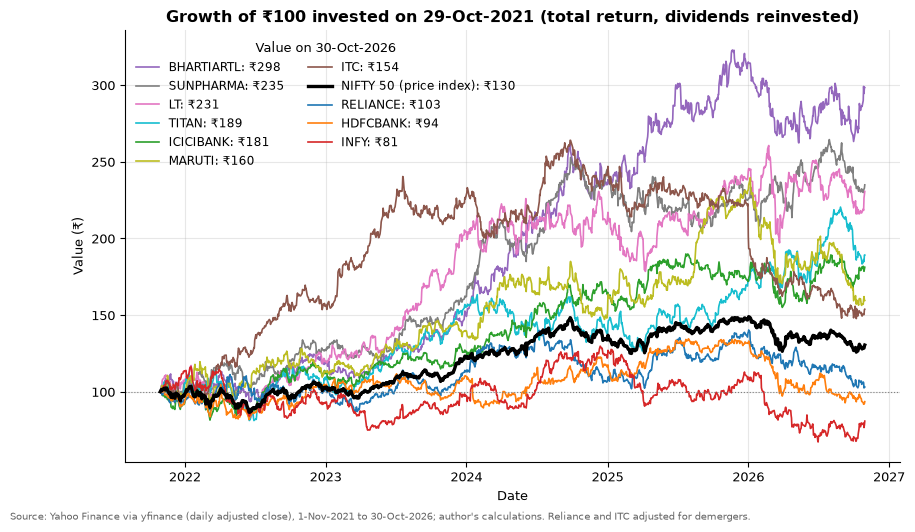

In [8]:
prices = clean.prices
rets, base = pf.window_returns(prices, ANALYSIS_START, ANALYSIS_END)
years = (rets.index[-1] - base).days / 365.25
print(f"Base date {base.date()}; returns from {rets.index[0].date()} to {rets.index[-1].date()}")
print(f"{len(rets)} daily returns over {years:.2f} years = {len(rets) / years:.1f} trading days a year")
assert rets.notna().all().all() and rets.index[-1] == ANALYSIS_END
growth = pf.wealth_index(rets, base)
print(growth.iloc[-1].sort_values(ascending=False).round(0).to_string())
fig = plotting.plot_cumulative_growth(growth, FIG_DIR / "cumulative_growth.png")

Bharti Airtel turned Rs 100 into about Rs 298 and Sun Pharma and L&T into about Rs 231-235, while Infosys (Rs 81), HDFC Bank (Rs 94) and Reliance (Rs 103) ended near or below where they started. The NIFTY 50 price index ended at Rs 130. Seven of the ten stocks beat the index.

## 4. Risk and return per stock

| Measure | Definition |
|---|---|
| Annualised mean | $252 \times \bar r$ |
| Standard error of the mean | $\sigma_{annual} / \sqrt{\text{years}}$ |
| CAGR | $(V_{end} / V_{start})^{1/\text{years}} - 1$, calendar years |
| Volatility | $\sqrt{252} \times s(r)$ |
| Sharpe | $252\,\overline{(r - r_f)} \,/\, (\sqrt{252}\, s(r))$, with $r_f = 1.0593^{1/252} - 1$ |
| Sortino | same numerator over $\sqrt{252}\sqrt{\overline{\min(r - r_f, 0)^2}}$ (downside deviation, target $r_f$) |
| Beta, Jensen's alpha, R-squared | OLS of $r - r_f = \alpha + \beta (r_m - r_f) + \varepsilon$; alpha annualised as $252\alpha$ |
| Treynor | annualised mean excess return / beta |
| Maximum drawdown | largest fall of the wealth index from a running peak |

In [9]:
weekly = pf.weekly_returns(prices, ANALYSIS_START, ANALYSIS_END)
stats = pf.asset_statistics(rets, weekly, BENCHMARK, base, RF_DAILY, RF_WEEKLY)
cols = ["ann_mean_return", "ann_mean_se", "cagr", "ann_volatility", "sharpe", "sortino", "treynor", "max_drawdown",
        "mdd_peak", "mdd_trough"]
display(fmt(stats[cols], pct=["ann_mean_return", "ann_mean_se", "cagr", "ann_volatility", "treynor", "max_drawdown"],
            dec=["sharpe", "sortino"]))

,ann_mean_return,ann_mean_se,cagr,ann_volatility,sharpe,sortino,treynor,max_drawdown,mdd_peak,mdd_trough
RELIANCE,3.1%,10.1%,0.6%,22.4%,-0.12,-0.17,-2.4%,-27.2%,2024-07-08,2025-03-04
HDFCBANK,0.9%,9.5%,-1.3%,21.1%,-0.23,-0.32,-4.6%,-31.7%,2025-07-30,2026-10-27
ICICIBANK,14.1%,8.8%,12.6%,19.5%,0.42,0.61,8.6%,-20.7%,2022-01-13,2022-03-07
INFY,-0.9%,11.9%,-4.2%,26.3%,-0.25,-0.35,-6.9%,-48.2%,2024-12-13,2026-07-01
BHARTIARTL,24.7%,9.7%,24.4%,21.6%,0.88,1.31,23.6%,-18.8%,2025-11-21,2026-05-12
ITC,10.7%,8.9%,9.0%,19.7%,0.25,0.37,7.6%,-44.1%,2024-09-26,2026-10-08
LT,20.1%,11.1%,18.2%,24.5%,0.58,0.84,11.9%,-28.9%,2022-01-17,2022-06-20
SUNPHARMA,19.4%,9.0%,18.6%,19.9%,0.69,1.03,24.5%,-19.1%,2024-09-27,2025-03-04
MARUTI,12.2%,10.5%,9.8%,23.3%,0.28,0.41,7.4%,-34.8%,2026-01-06,2026-10-22
TITAN,15.8%,10.6%,13.6%,23.4%,0.43,0.62,11.0%,-28.6%,2022-03-22,2022-06-29


In [10]:
# Dividends missing from the price index: compare NIFTYBEES (dividends stay in the ETF's NAV) with ^NSEI
tr = clean.tr_proxy
px = prices[BENCHMARK]
cagr_px = (px.loc[ANALYSIS_END] / px.loc[base]) ** (1 / years) - 1
cagr_tr = (tr.loc[ANALYSIS_END] / tr.loc[base]) ** (1 / years) - 1
nifty = stats.loc[BENCHMARK]
sharpe_tr = (nifty["ann_mean_return"] + (cagr_tr - cagr_px) - RF_ARITH) / nifty["ann_volatility"]
print(f"NIFTY 50 price index CAGR {cagr_px:.2%}; NIFTYBEES CAGR {cagr_tr:.2%}; gap {cagr_tr - cagr_px:.2%} a year")
print(f"NIFTY Sharpe: price index {nifty['sharpe']:.2f}; approximate total-return basis {sharpe_tr:.2f}")

NIFTY 50 price index CAGR 5.46%; NIFTYBEES CAGR 6.58%; gap 1.12% a year
NIFTY Sharpe: price index 0.05; approximate total-return basis 0.13


- **Bharti Airtel** had the best record: 24.4% CAGR, Sharpe 0.88 and the smallest drawdown among the ten stocks (-18.8%). It is the only stock whose Jensen's alpha is statistically different from zero at the 5% level (t = 2.20).
- **Infosys, HDFC Bank and Reliance** earned less than the T-bill rate, so their Sharpe, Sortino and Treynor ratios are negative. Infosys fell 48% from its December-2024 peak.
- **NIFTY 50** returned 5.5% a year as a price index, slightly below the T-bill rate, so its Sharpe ratio is only 0.05. Dividends explain part of that: NIFTYBEES grew 1.1 percentage points a year faster, which lifts the index's Sharpe ratio to about 0.13. The stocks' figures include dividends, so the price index understates the benchmark by roughly that amount.
- **Volatility drag:** the arithmetic mean exceeds CAGR by about $\sigma^2/2$. Infosys has a -0.9% mean but a -4.2% CAGR at 26% volatility.
- **Noise:** the standard error of a five-year annualised mean is 9-12 percentage points for these stocks. Bharti Airtel's 95% confidence interval runs from about 6% to 44% a year. This matters for the optimisation below.

## 5. Beta: daily vs weekly returns

A daily beta can be biased when prices do not move in sync. If a stock reacts to market news a day late, part of its co-movement with the index lands in the next day's return, and a regression on same-day returns misses it (Scholes and Williams, 1977; Dimson, 1979). Weekly returns give a lagged reaction time to show up inside the same interval. The Dimson beta adds the slopes on the previous, same and next day's market return. Weekly betas use 261 observations instead of 1,234, so their standard errors are about twice as large.

In [11]:
b = stats.loc[STOCK_LABELS, ["beta_daily", "beta_daily_se", "beta_weekly", "beta_weekly_se", "beta_dimson",
                             "r_squared", "r_squared_weekly", "jensen_alpha_ann", "alpha_t_stat"]].copy()
b["(weekly - daily) / s.e."] = (b["beta_weekly"] - b["beta_daily"]) / b["beta_weekly_se"]
display(fmt(b.sort_values("beta_daily", ascending=False), pct=["jensen_alpha_ann"],
            dec=[c for c in b.columns if c != "jensen_alpha_ann"]))
print("Highest daily beta:", b["beta_daily"].idxmax(), f"{b['beta_daily'].max():.2f};",
      "lowest:", b["beta_daily"].idxmin(), f"{b['beta_daily'].min():.2f}")

,beta_daily,beta_daily_se,beta_weekly,beta_weekly_se,beta_dimson,r_squared,r_squared_weekly,jensen_alpha_ann,alpha_t_stat,(weekly - daily) / s.e.
LT,1.20,0.04,1.22,0.09,1.22,0.46,0.44,13.6%,1.67,0.24
RELIANCE,1.11,0.03,1.05,0.08,1.10,0.48,0.42,-3.3%,-0.46,-0.77
HDFCBANK,1.06,0.03,1.01,0.07,1.07,0.49,0.46,-5.6%,-0.82,-0.86
ICICIBANK,0.97,0.03,1.07,0.06,1.04,0.47,0.52,7.7%,1.20,1.57
INFY,0.97,0.05,0.93,0.11,0.96,0.26,0.22,-7.2%,-0.71,-0.34
TITAN,0.91,0.04,1.11,0.09,1.02,0.29,0.36,9.4%,1.06,2.21
MARUTI,0.88,0.04,0.89,0.10,0.95,0.27,0.24,5.9%,0.66,0.11
BHARTIARTL,0.80,0.04,0.82,0.08,0.77,0.27,0.30,18.4%,2.20,0.28
ITC,0.65,0.04,0.61,0.08,0.56,0.21,0.17,4.6%,0.58,-0.48
SUNPHARMA,0.56,0.04,0.62,0.08,0.57,0.15,0.17,13.3%,1.61,0.77


Highest daily beta: LT 1.20; lowest: SUNPHARMA 0.56


- **Highest beta:** L&T (1.20 daily, 1.22 weekly). **Lowest beta:** Sun Pharma (0.56 daily, 0.62 weekly).
- For eight of the ten stocks the weekly beta is within one standard error of the daily beta. **Titan** is the clear exception (0.91 daily, 1.11 weekly, 2.2 standard errors apart) and **ICICI Bank** is borderline (0.97 vs 1.07). Both have Dimson betas (1.02 and 1.04) above their daily betas, which fits a delayed reaction to market moves.
- For Reliance, HDFC Bank and Infosys, three of the largest NIFTY 50 constituents ([Times Now, Jun-2026](https://www.timesnownews.com/business-economy/markets/how-icici-bank-surpassed-reliance-industries-to-become-nifty-50s-second-highest-weighted-stock-despite-a-smaller-market-cap-explained-article-154530028)), the weekly beta is slightly lower than the daily one, by less than one standard error. Non-synchronous trading predicts little difference for large, frequently traded stocks, and that is what the data shows.
- R-squared ranges from 0.15 (Sun Pharma) to 0.49 (HDFC Bank): most of each stock's daily variance is stock-specific, which is what diversification removes.

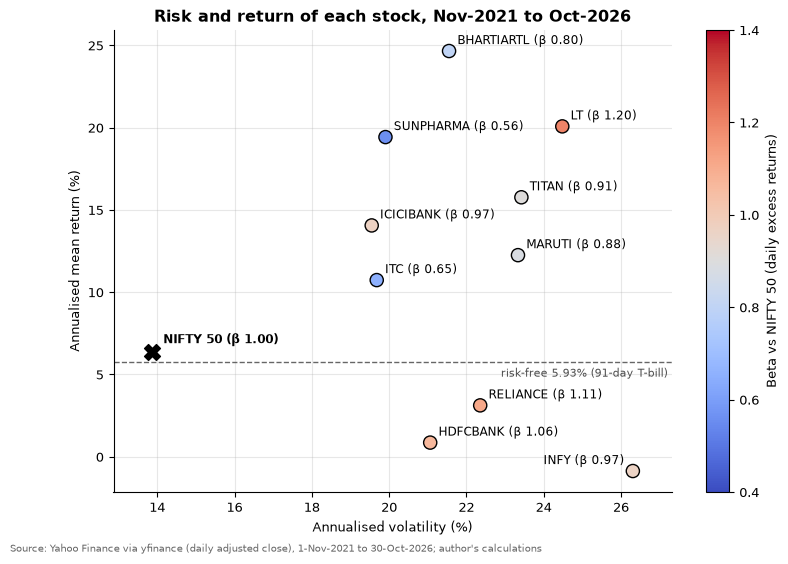

In [12]:
fig = plotting.plot_risk_return(stats, FIG_DIR / "risk_return.png")

## 6. Correlation

Average pairwise correlation of the 10 stocks: 0.29 (lowest 0.13, highest 0.51)
Average stock volatility 22.2%; equal-weight portfolio volatility 13.3%


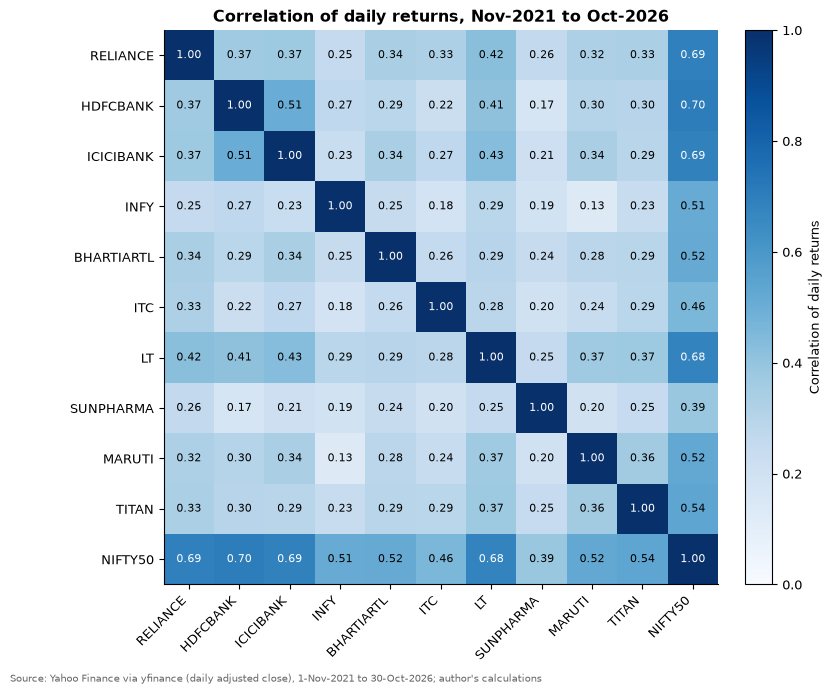

In [13]:
corr = rets.corr()
c10 = corr.loc[STOCK_LABELS, STOCK_LABELS].to_numpy()[np.triu_indices(len(STOCK_LABELS), 1)]
ew_vol = pf.annualised_vol(rets[STOCK_LABELS].mean(axis=1))
print(f"Average pairwise correlation of the 10 stocks: {c10.mean():.2f} (lowest {c10.min():.2f}, highest {c10.max():.2f})")
print(f"Average stock volatility {stats.loc[STOCK_LABELS, 'ann_volatility'].mean():.1%}; "
      f"equal-weight portfolio volatility {ew_vol:.1%}")
fig = plotting.plot_correlation_heatmap(corr, FIG_DIR / "correlation_heatmap.png")

The stocks are only loosely correlated: 0.29 on average, from 0.13 (Infosys and Maruti) to 0.51 (HDFC Bank and ICICI Bank, the two private banks). That is why an equal-weight mix of stocks that each have about 22% volatility ends up near 13%.

## 7. Optimal portfolios

Inputs are estimated from the full window: $\mu = 252 \times$ mean daily return and $\Sigma = 252 \times$ the sample covariance of daily returns. All portfolios are long-only ($w_i \ge 0$) and fully invested ($\sum w_i = 1$); the capped versions add $w_i \le 20\%$. Each problem is solved with `scipy.optimize.minimize(method="SLSQP")`, analytic gradients and several starting points.

- **Equal weight:** 10% in each stock every day. Holding constant weights means rebalancing daily, an approximation: real portfolios drift between rebalances and pay costs when they trade.
- **Global minimum variance (GMV):** minimise $w^\top \Sigma w$.
- **Maximum Sharpe (tangency):** maximise $(w^\top \mu - r_f) / \sqrt{w^\top \Sigma w}$ with $r_f$ = 5.76% (the daily rate on the same x252 basis as $\mu$).

In [14]:
R = rets[STOCK_LABELS]
mu, cov = estimate_inputs(R)
weights = optimise_set(mu, cov)
assert np.allclose(weights.sum(), 1.0, atol=1e-10), "weights must sum to 1"
assert (weights.to_numpy() >= 0).all(), "long-only"
assert (weights[["min_variance_cap20", "max_sharpe_cap20"]].to_numpy() <= WEIGHT_CAP + 1e-9).all(), "20% cap"
display(fmt(weights.rename(columns=PORTFOLIO_NAMES), pct=PORTFOLIO_NAMES.values()))

,Equal weight,Min variance,Max Sharpe,Min variance (20% cap),Max Sharpe (20% cap)
RELIANCE,10.0%,2.5%,0.0%,3.0%,0.0%
HDFCBANK,10.0%,10.9%,0.0%,11.1%,0.0%
ICICIBANK,10.0%,12.7%,0.0%,13.3%,18.0%
INFY,10.0%,7.8%,0.0%,8.2%,0.0%
BHARTIARTL,10.0%,10.0%,48.2%,10.6%,20.0%
ITC,10.0%,20.8%,0.0%,20.0%,7.4%
LT,10.0%,0.0%,16.3%,0.0%,20.0%
SUNPHARMA,10.0%,22.6%,34.3%,20.0%,20.0%
MARUTI,10.0%,8.4%,0.0%,8.7%,0.2%
TITAN,10.0%,4.6%,1.2%,5.1%,14.4%


In [15]:
port_returns = pd.DataFrame({k: pf.portfolio_returns(R, weights[k]) for k in weights})
port_returns[BENCHMARK] = rets[BENCHMARK]
pstats = summarise_portfolios(port_returns, weights, mu, cov, rets[BENCHMARK], base)
display(fmt(pstats[["ann_mean_return", "cagr", "ann_volatility", "sharpe", "sortino", "beta", "jensen_alpha_ann",
                    "max_drawdown", "effective_n", "n_holdings"]],
            pct=["ann_mean_return", "cagr", "ann_volatility", "jensen_alpha_ann", "max_drawdown"],
            dec=["sharpe", "sortino", "beta", "effective_n"]))

,ann_mean_return,cagr,ann_volatility,sharpe,sortino,beta,jensen_alpha_ann,max_drawdown,effective_n,n_holdings
Equal weight,12.0%,11.5%,13.3%,0.47,0.67,0.91,5.7%,-17.6%,10.00,10.0
Min variance,12.7%,12.4%,12.6%,0.55,0.79,0.80,6.4%,-17.9%,6.78,9.0
Max Sharpe,22.0%,22.5%,15.7%,1.03,1.54,0.78,15.7%,-16.4%,2.66,4.0
Min variance (20% cap),12.5%,12.1%,12.6%,0.54,0.77,0.81,6.2%,-18.1%,7.20,9.0
Max Sharpe (20% cap),18.4%,18.6%,14.0%,0.91,1.32,0.87,12.1%,-14.7%,5.60,7.0
NIFTY 50,6.4%,5.5%,13.9%,0.05,0.06,1.00,0.0%,-16.5%,,NaN


The tangency portfolio holds only four stocks: Bharti Airtel 48%, Sun Pharma 34%, L&T 16% and Titan 1%. Its in-sample Sharpe ratio is 1.03, against 0.47 for equal weight and 0.05 for NIFTY. The minimum-variance portfolio spreads across nine stocks and leans on the two lowest-beta names, Sun Pharma (23%) and ITC (21%).

**What drives the weights.** At the long-only optimum, every stock held earns an excess return exactly proportional to its beta against the tangency portfolio, $\mu_i - r_f = \beta_{i,T}(\mu_T - r_f)$; every stock left out falls short of that line. The table checks this and shows each stock's share of portfolio risk. Bharti Airtel combines the highest mean return with a low correlation to the others, so it supplies 56% of the portfolio's variance. ICICI Bank misses by only 0.45 percentage points a year, a tiny fraction of its 8.8-point standard error.

In [16]:
m, c = mu.to_numpy(), cov.to_numpy()
w_t = weights["max_sharpe"].to_numpy()
kkt = pf.tangency_kkt_table(w_t, m, c, RF_ARITH, STOCK_LABELS)
kkt["share_of_risk"] = pf.risk_contributions(w_t, c)
display(fmt(kkt, pct=["weight", "excess_return", "required_excess_return", "shortfall", "share_of_risk"],
            dec=["beta_vs_tangency"]))

# Sensitivity: small, plausible changes to one expected return
se = stats.loc[STOCK_LABELS, "ann_mean_se"]
cases = {"base case": mu.copy()}
cases["Bharti mean - 1 s.e."] = mu.copy()
cases["Bharti mean - 1 s.e."]["BHARTIARTL"] -= se["BHARTIARTL"]
cases["ICICI mean + 1 pp"] = mu.copy()
cases["ICICI mean + 1 pp"]["ICICIBANK"] += 0.01
sens = pd.DataFrame({k: pf.max_sharpe(v.to_numpy(), c, RF_ARITH) for k, v in cases.items()}, index=STOCK_LABELS)
print(f"Bharti Airtel standard error of the mean: {se['BHARTIARTL']:.1%}")
display(fmt(sens, pct=sens.columns))

,weight,excess_return,beta_vs_tangency,required_excess_return,shortfall,share_of_risk
RELIANCE,0.0%,-2.6%,0.64,10.4%,-13.1%,0.0%
HDFCBANK,0.0%,-4.9%,0.50,8.1%,-13.0%,0.0%
ICICIBANK,0.0%,8.3%,0.54,8.7%,-0.5%,0.0%
INFY,0.0%,-6.6%,0.54,8.8%,-15.5%,0.0%
BHARTIARTL,48.2%,18.9%,1.16,18.9%,-0.0%,56.1%
ITC,0.0%,5.0%,0.42,6.8%,-1.8%,0.0%
LT,16.3%,14.3%,0.88,14.3%,0.0%,14.4%
SUNPHARMA,34.3%,13.7%,0.84,13.7%,0.0%,28.8%
MARUTI,0.0%,6.5%,0.56,9.0%,-2.6%,0.0%
TITAN,1.2%,10.0%,0.62,10.0%,-0.0%,0.7%


Bharti Airtel standard error of the mean: 9.7%


,base case,Bharti mean - 1 s.e.,ICICI mean + 1 pp
RELIANCE,0.0%,0.0%,0.0%
HDFCBANK,0.0%,0.0%,0.0%
ICICIBANK,0.0%,8.4%,2.9%
INFY,0.0%,0.0%,0.0%
BHARTIARTL,48.2%,11.6%,47.1%
ITC,0.0%,0.0%,0.0%
LT,16.3%,24.6%,15.4%
SUNPHARMA,34.3%,47.4%,33.7%
MARUTI,0.0%,0.0%,0.0%
TITAN,1.2%,8.1%,0.9%


The sensitivity table makes the point concrete: moving one expected return by an amount well inside its own standard error reshuffles the tangency weights. Mean-variance optimisation treats the sample means as known, so it puts the most money where estimation error happens to be most favourable (Michaud, 1989).

## 8. Efficient frontier, Monte Carlo cloud and capital market line

- **Frontier:** minimise $w^\top \Sigma w$ subject to $w^\top \mu$ = target for 60 targets from the GMV return to the highest achievable return (100% in Bharti Airtel), plus 20 targets below the GMV for the inefficient lower branch. The capped frontier repeats this with $w_i \le 20\%$, whose highest achievable return is 20% in each of the five best stocks.
- **Monte Carlo cloud:** 20,000 weight vectors drawn from a Dirichlet(1, ..., 1) distribution, which is uniform over all long-only, fully invested portfolios; seed 42.
- **Capital market line (CML):** $r_f + S_T\,\sigma$, where $S_T$ is the tangency Sharpe ratio.

GMV: return 12.70%, volatility 12.57%; tangency: return 22.01%, volatility 15.70%, Sharpe 1.035
Best random portfolio Sharpe 0.943; lowest random volatility 12.65%
Random portfolios with Sharpe above NIFTY: 98.6%; above equal weight: 44.9%
Capped tangency Sharpe 0.906 (cost of the cap 0.129)
All frontier and Monte Carlo checks PASS


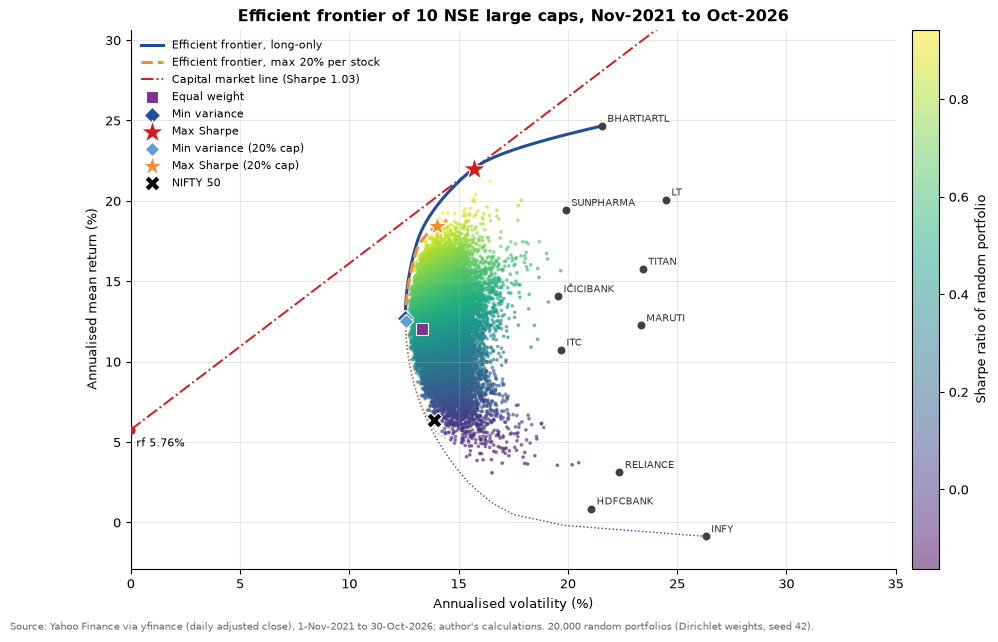

In [17]:
fr = pf.efficient_frontier(m, c, RF_ARITH, 1.0, N_FRONTIER, N_FRONTIER_LOWER, STOCK_LABELS)
fr_cap = pf.efficient_frontier(m, c, RF_ARITH, WEIGHT_CAP, N_FRONTIER, N_FRONTIER_LOWER, STOCK_LABELS)
frontier = pd.concat([fr.assign(frontier="long-only"), fr_cap.assign(frontier="long-only, 20% cap")],
                     ignore_index=True)
mc, mc_w = pf.random_portfolios(m, c, RF_ARITH, N_MONTE_CARLO, SEED)
ret_t, vol_t, s_t = pf.portfolio_point(w_t, m, c)
ret_g, vol_g, s_g = pf.portfolio_point(weights["min_variance"].to_numpy(), m, c)
s_tc = pf.portfolio_point(weights["max_sharpe_cap20"].to_numpy(), m, c)[2]

# Validation of the frontier and the cloud
for name, f in (("long-only", fr), ("20% cap", fr_cap)):
    eff = f[f["branch"] == "efficient"].sort_values("return")
    assert (np.diff(eff["volatility"].to_numpy()) >= -1e-9).all(), f"{name}: volatility must rise above the GMV"
    assert np.allclose(f[STOCK_LABELS].sum(axis=1), 1) and (f[STOCK_LABELS].to_numpy() >= -1e-10).all()
assert np.allclose(mc_w.sum(axis=1), 1) and (mc_w >= 0).all()
assert s_t >= mc["sharpe"].max() - 1e-9, "tangency must beat every random portfolio"
assert s_t >= fr["sharpe"].max() - 1e-9 and s_tc >= fr_cap["sharpe"].max() - 1e-9
assert vol_g <= mc["volatility"].min() + 1e-9
print(f"GMV: return {ret_g:.2%}, volatility {vol_g:.2%}; tangency: return {ret_t:.2%}, volatility {vol_t:.2%}, Sharpe {s_t:.3f}")
print(f"Best random portfolio Sharpe {mc['sharpe'].max():.3f}; lowest random volatility {mc['volatility'].min():.2%}")
print(f"Random portfolios with Sharpe above NIFTY: {(mc['sharpe'] > stats.at[BENCHMARK, 'sharpe']).mean():.1%}; "
      f"above equal weight: {(mc['sharpe'] > pstats.at['Equal weight', 'sharpe']).mean():.1%}")
print(f"Capped tangency Sharpe {s_tc:.3f} (cost of the cap {s_t - s_tc:.3f})")
print("All frontier and Monte Carlo checks PASS")

points = {PORTFOLIO_NAMES[k]: pf.portfolio_point(weights[k].to_numpy(), m, c)[1::-1] for k in weights}
points["NIFTY 50"] = (stats.at[BENCHMARK, "ann_volatility"], stats.at[BENCHMARK, "ann_mean_return"])
fig = plotting.plot_efficient_frontier(frontier, mc, points, stats.loc[STOCK_LABELS], s_t,
                                       path=FIG_DIR / "efficient_frontier.png")

- The random portfolios cluster around equal weight because Dirichlet(1) draws rarely concentrate. The best of 20,000 reaches a Sharpe ratio of 0.94, below the tangency's 1.03, and none has lower volatility than the GMV (12.57%).
- 98.6% of random portfolios have a higher Sharpe ratio than NIFTY in this sample. That says more about the sample than about the method: the ten stocks were chosen in 2026 from today's large caps, and the cap-weighted index carried large weights in stocks that lagged.
- The 20% cap moves the frontier slightly to the right and lowers its top end. It costs 0.13 of in-sample Sharpe ratio (1.03 to 0.91) and spreads the tangency portfolio over seven stocks (effective number of holdings 5.6 instead of 2.7). Section 10 shows that the cap helped out of sample.

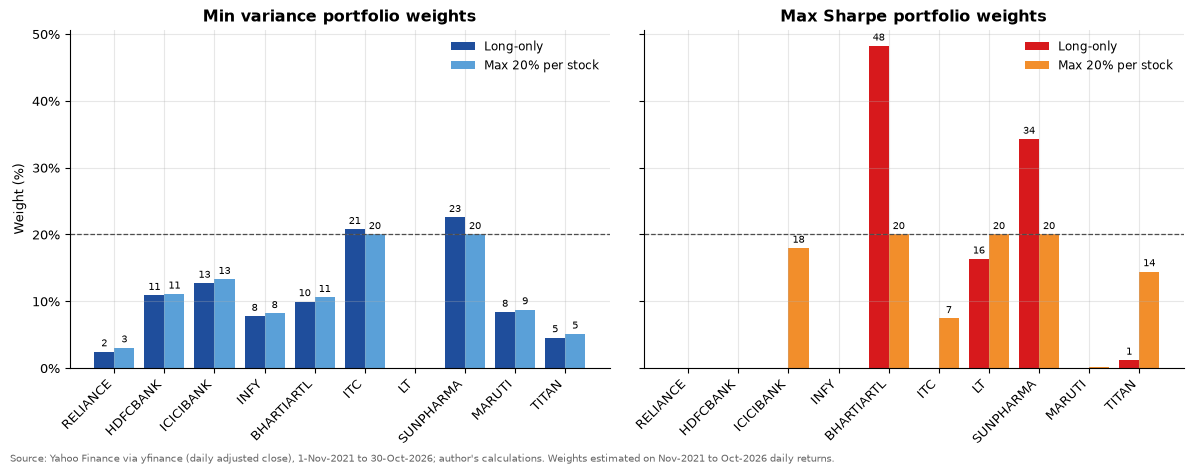

In [18]:
fig = plotting.plot_weights(weights, FIG_DIR / "optimal_weights.png")

## 9. Drawdowns

,max_drawdown,peak,trough,recovery
Max Sharpe,-16.4%,06-Apr-2022,17-Jun-2022,08-Sep-2022
Max Sharpe (20% cap),-14.7%,06-Apr-2022,17-Jun-2022,29-Jul-2022
Equal weight,-17.6%,22-Dec-2025,08-Oct-2026,not yet
Min variance,-17.9%,05-Dec-2025,08-Oct-2026,not yet
NIFTY 50,-16.5%,17-Jan-2022,17-Jun-2022,11-Nov-2022


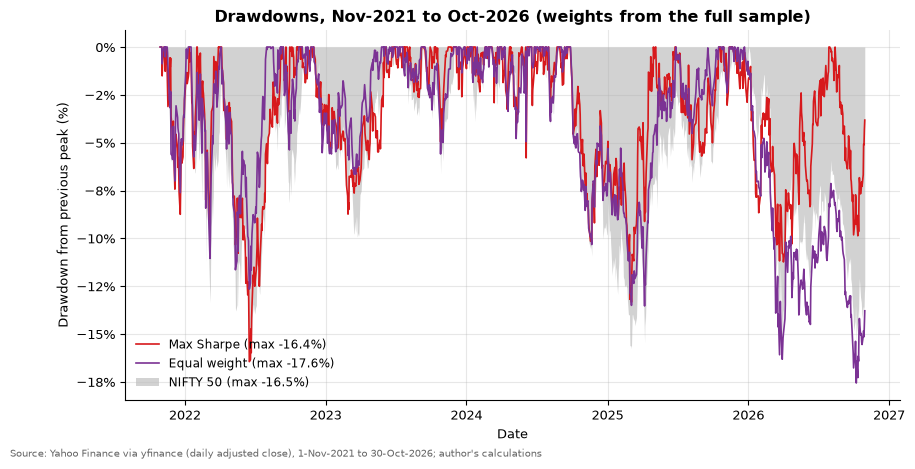

In [19]:
dd = pd.DataFrame({PORTFOLIO_NAMES[k]: pf.drawdown_series(port_returns[k], base) for k in ["max_sharpe", "equal_weight"]})
dd["NIFTY 50"] = pf.drawdown_series(rets[BENCHMARK], base)
series = {"Max Sharpe": port_returns["max_sharpe"], "Max Sharpe (20% cap)": port_returns["max_sharpe_cap20"],
          "Equal weight": port_returns["equal_weight"], "Min variance": port_returns["min_variance"],
          "NIFTY 50": rets[BENCHMARK]}
mdd = pd.DataFrame({k: pf.max_drawdown(v, base) for k, v in series.items()}).T
mdd["max_drawdown"] = mdd["max_drawdown"].astype(float)
for col in ["peak", "trough", "recovery"]:
    mdd[col] = mdd[col].map(lambda d: "not yet" if pd.isna(d) else pd.Timestamp(d).strftime("%d-%b-%Y"))
display(fmt(mdd, pct=["max_drawdown"]))
fig = plotting.plot_drawdowns(dd, FIG_DIR / "drawdowns.png")

With hindsight weights, the tangency portfolio's worst fall (-16.4%, April to June 2022) is about the same as NIFTY's (-16.5%, January to June 2022), even though its volatility is higher (15.7% vs 13.9%). In the 2026 sell-off its stocks fell less (-11.2% against -15.6% for NIFTY), while equal weight and minimum variance had their worst drawdowns then (-17.6% and -17.9%), still not recovered on 30-Oct-2026. The capped tangency portfolio had the smallest maximum drawdown (-14.7%). These are in-sample results: the weights were chosen knowing how the stocks performed.

## 10. Out-of-sample test

The weights above use information an investor did not have. To test them honestly:

1. estimate $\mu$ and $\Sigma$ on 1-Nov-2021 to 31-Oct-2024 (742 trading days) and solve for GMV, max Sharpe and max Sharpe with the 20% cap;
2. hold those weights from 1-Nov-2024 to 30-Oct-2026 (492 trading days) with no re-estimation;
3. compare with equal weight and NIFTY. The main table rebalances to the fixed weights daily (the same assumption as the optimiser); a buy-and-hold version that lets weights drift follows.

In [20]:
w_is, oos_table, oos_growth, oos_base = out_of_sample(prices)
display(fmt(w_is.rename(columns=PORTFOLIO_NAMES), pct=[PORTFOLIO_NAMES[k] for k in w_is]))
cols = ["portfolio", "cagr", "ann_mean_return", "ann_volatility", "sharpe", "max_drawdown"]
pc = ["cagr", "ann_mean_return", "ann_volatility", "max_drawdown"]
for period in oos_table["period"].unique():
    t = oos_table[(oos_table["period"] == period) & (oos_table["rebalancing"] != "buy-and-hold")]
    print(period, "(daily rebalancing)")
    display(fmt(t[cols].set_index("portfolio"), pct=pc, dec=["sharpe"]))
bh = oos_table[oos_table["rebalancing"] == "buy-and-hold"]
print("out-of-sample, buy-and-hold (weights drift)")
display(fmt(bh[cols].set_index("portfolio"), pct=pc, dec=["sharpe"]))

,Equal weight,Min variance,Max Sharpe,Max Sharpe (20% cap)
RELIANCE,10.0%,2.0%,0.0%,0.0%
HDFCBANK,10.0%,11.5%,0.0%,0.0%
ICICIBANK,10.0%,9.2%,0.0%,14.1%
INFY,10.0%,8.1%,0.0%,0.0%
BHARTIARTL,10.0%,11.3%,25.2%,20.0%
ITC,10.0%,21.3%,35.5%,20.0%
LT,10.0%,0.0%,6.3%,20.0%
SUNPHARMA,10.0%,23.0%,33.0%,20.0%
MARUTI,10.0%,9.0%,0.0%,5.9%
TITAN,10.0%,4.6%,0.0%,0.0%


in-sample (Nov-2021 to Oct-2024) (daily rebalancing)


,cagr,ann_mean_return,ann_volatility,sharpe,max_drawdown
portfolio,,,,,
Equal weight,20.2%,19.7%,13.6%,1.03,-12.7%
Min variance,24.6%,23.3%,12.8%,1.37,-10.6%
Max Sharpe,35.3%,31.9%,14.0%,1.86,-9.6%
Max Sharpe (20% cap),31.1%,28.6%,13.8%,1.65,-10.7%
NIFTY 50,11.0%,11.7%,14.2%,0.42,-16.5%


out-of-sample (Nov-2024 to Oct-2026) (daily rebalancing)


,cagr,ann_mean_return,ann_volatility,sharpe,max_drawdown
portfolio,,,,,
Equal weight,-0.4%,0.4%,12.9%,-0.42,-17.6%
Min variance,-3.8%,-3.2%,12.2%,-0.74,-18.6%
Max Sharpe,-4.4%,-3.7%,13.7%,-0.69,-17.1%
Max Sharpe (20% cap),0.3%,1.1%,13.2%,-0.35,-15.4%
NIFTY 50,-2.4%,-1.6%,13.3%,-0.56,-15.6%


out-of-sample, buy-and-hold (weights drift)


,cagr,ann_mean_return,ann_volatility,sharpe,max_drawdown
portfolio,,,,,
Equal weight,-0.6%,0.2%,13.0%,-0.43,-17.4%
Min variance,-3.7%,-3.1%,12.1%,-0.74,-18.3%
Max Sharpe,-3.7%,-2.9%,13.7%,-0.63,-16.4%
Max Sharpe (20% cap),0.3%,1.1%,13.3%,-0.35,-15.5%


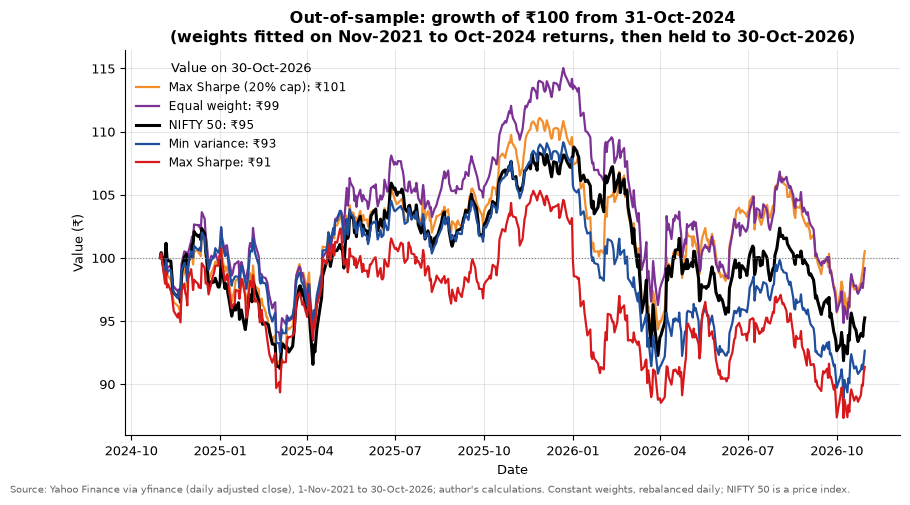

In [21]:
fig = plotting.plot_oos_growth(oos_growth, FIG_DIR / "out_of_sample_growth.png")

In [22]:
# Why the fitted weights failed: means do not persist, risk does
is_r, _ = pf.window_returns(prices, ANALYSIS_START, IS_END)
oos_r, _ = pf.window_returns(prices, OOS_START, ANALYSIS_END)
comp = pd.DataFrame({"mean Nov21-Oct24": pf.annualised_mean(is_r), "mean Nov24-Oct26": pf.annualised_mean(oos_r),
                     "vol Nov21-Oct24": pf.annualised_vol(is_r), "vol Nov24-Oct26": pf.annualised_vol(oos_r)})
display(fmt(comp, pct=comp.columns))
s10 = comp.loc[STOCK_LABELS]
rho_mean = s10["mean Nov21-Oct24"].rank().corr(s10["mean Nov24-Oct26"].rank())
rho_vol = s10["vol Nov21-Oct24"].rank().corr(s10["vol Nov24-Oct26"].rank())
iu = np.triu_indices(len(STOCK_LABELS), 1)
rho_corr = np.corrcoef(is_r[STOCK_LABELS].corr().to_numpy()[iu], oos_r[STOCK_LABELS].corr().to_numpy()[iu])[0, 1]
print(f"Rank correlation between the two periods: mean returns {rho_mean:.2f}, volatilities {rho_vol:.2f}; "
      f"correlation of the 45 pairwise correlations {rho_corr:.2f}")

mu_is, cov_is = estimate_inputs(is_r[STOCK_LABELS])
oos_daily = oos_table[(oos_table["period"].str.startswith("out")) & (oos_table["rebalancing"] == "daily")].set_index("portfolio")
exante = pd.DataFrame({PORTFOLIO_NAMES[k]: pf.portfolio_point(w_is[k].to_numpy(), mu_is.to_numpy(), cov_is.to_numpy())
                       for k in w_is}, index=["expected return", "expected volatility", "expected Sharpe"]).T
exante["realised mean"] = oos_daily.loc[exante.index, "ann_mean_return"]
exante["realised volatility"] = oos_daily.loc[exante.index, "ann_volatility"]
exante["realised Sharpe"] = oos_daily.loc[exante.index, "sharpe"]
display(fmt(exante, pct=["expected return", "expected volatility", "realised mean", "realised volatility"],
            dec=["expected Sharpe", "realised Sharpe"]))

,mean Nov21-Oct24,mean Nov24-Oct26,vol Nov21-Oct24,vol Nov24-Oct26
RELIANCE,8.0%,-4.2%,23.2%,21.1%
HDFCBANK,6.8%,-8.1%,21.9%,19.8%
ICICIBANK,19.0%,6.5%,20.3%,18.3%
INFY,7.5%,-13.5%,24.6%,28.7%
BHARTIARTL,31.9%,13.7%,21.7%,21.3%
ITC,32.6%,-22.3%,19.7%,19.4%
LT,28.5%,7.3%,24.6%,24.3%
SUNPHARMA,31.7%,0.9%,19.8%,20.0%
MARUTI,17.0%,5.1%,23.8%,22.6%
TITAN,13.9%,18.6%,23.9%,22.7%


Rank correlation between the two periods: mean returns 0.19, volatilities 0.88; correlation of the 45 pairwise correlations 0.79


,expected return,expected volatility,expected Sharpe,realised mean,realised volatility,realised Sharpe
Equal weight,19.7%,13.6%,1.03,0.4%,12.9%,-0.42
Min variance,23.3%,12.8%,1.37,-3.2%,12.2%,-0.74
Max Sharpe,31.9%,14.0%,1.86,-3.7%,13.7%,-0.69
Max Sharpe (20% cap),28.6%,13.8%,1.65,1.1%,13.2%,-0.35


**Estimation error, plainly.** In 2021-24 ITC, Bharti Airtel and Sun Pharma each returned over 30% a year, so the fitted tangency portfolio put 94% of its money in them (ITC 35%, Sun Pharma 33%, Bharti 25%). In 2024-26 ITC fell 38% (cigarette tax shock in January 2026) and Sun Pharma was flat, and the portfolio lost 4.4% a year, worse than NIFTY (-2.4%) and equal weight (-0.4%). Its expected Sharpe ratio of 1.86 became -0.69.

The risk side held up. Each portfolio's realised volatility came within one percentage point of its forecast, the volatility ranking of the stocks barely changed between periods (rank correlation 0.88) and the pairwise correlations were similar (0.79). The return ranking did not persist (0.19). Mean-variance optimisation is most sensitive to the input that is hardest to estimate.

Two simple guards worked better here. Equal weight, which ignores the means, lost only 0.4% a year. The 20% cap forced the optimiser to diversify and was the only fitted portfolio to end slightly above Rs 100 (CAGR +0.3%). Studies on longer samples find the same pattern: optimised portfolios rarely beat 1/N out of sample once estimation error is counted (DeMiguel, Garlappi and Uppal, 2009), and weight caps act like shrinkage of the covariance estimates (Jagannathan and Ma, 2003).

Two cautions. First, this is one two-year hold-out in a weak market, which is far too short to rank strategies. Second, with negative excess returns the Sharpe ratio can rank a riskier loss above a safer one, so CAGR and drawdown should be read alongside it.

## 11. Validation checks

`run_analysis()` (the pipeline behind `src/run_all.py`) recomputes everything from the cleaned prices and runs the full list of checks. The last cell confirms the notebook and the script produce identical numbers.

In [23]:
res = run_analysis(clean)
display(res.checks)
assert (res.checks["result"] == "PASS").all(), "a validation check failed"
print(f"{len(res.checks)} of {len(res.checks)} checks PASS")

,check,result,detail
0,Weights sum to 1 (all portfolios),PASS,max |sum-1| = 1.1e-16
1,Weights >= 0 (long-only),PASS,min weight = 0.0e+00
2,Capped weights <= 20%,PASS,max capped weight = 0.2000
3,Frontier weights sum to 1 and >= 0,PASS,160 frontier portfolios
4,Monte Carlo weights sum to 1 and >= 0,PASS,"20,000 portfolios"
5,Frontier volatility non-decreasing above min variance (long-only),PASS,smallest step = 9.94e-06
6,No frontier point below the min-variance volatility (long-only),PASS,min vol 12.5657% vs GMV 12.5657%
7,"Frontier volatility non-decreasing above min variance (long-only, 20% cap)",PASS,smallest step = 3.05e-06
8,"No frontier point below the min-variance volatility (long-only, 20% cap)",PASS,min vol 12.5780% vs GMV 12.5780%
9,Tangency Sharpe >= every Monte Carlo Sharpe,PASS,tangency 1.0347 vs best random 0.9426


20 of 20 checks PASS


In [24]:
# Notebook vs pipeline: identical inputs and functions must give identical results
assert np.allclose(res.weights.to_numpy(), weights.to_numpy(), atol=1e-12)
assert np.allclose(res.stats[stats.columns.drop(["mdd_peak", "mdd_trough"])].astype(float).to_numpy(),
                   stats[stats.columns.drop(["mdd_peak", "mdd_trough"])].astype(float).to_numpy(), equal_nan=True)
assert np.allclose(res.frontier[["return", "volatility", "sharpe"]].to_numpy(),
                   frontier[["return", "volatility", "sharpe"]].to_numpy())
assert np.allclose(res.mc.to_numpy(), mc.to_numpy())
assert np.allclose(res.oos_table.select_dtypes("number").to_numpy(), oos_table.select_dtypes("number").to_numpy())
print("PASS: notebook results match src/run_all.py")

PASS: notebook results match src/run_all.py


## 12. Takeaways and limitations

**Takeaways**

- Over Nov-2021 to Oct-2026 the hindsight tangency portfolio (Bharti Airtel, Sun Pharma, L&T) had a Sharpe ratio of 1.03 against 0.05 for the NIFTY 50 price index (about 0.13 with dividends) and 0.47 for equal weight.
- Betas ranged from 0.56 (Sun Pharma) to 1.20 (L&T). Daily and weekly betas agree within sampling error for most stocks; Titan is the one clear case of a higher weekly beta.
- Fitted on 2021-24 and held through 2024-26, the optimised portfolios lost money and trailed equal weight. Estimated volatilities and correlations carried over between periods; estimated mean returns did not.
- Concentration is the cost of chasing the highest in-sample Sharpe ratio: effective holdings fall to 2.7 stocks. A simple 20% cap gave up a little in-sample Sharpe and did better out of sample.

**Limitations**

- Historical means are noisy (standard errors of 9-12 percentage points a year over five years), so every optimised weight carries wide uncertainty.
- Five years is one market regime; the out-of-sample test covers only two years.
- Survivorship and selection bias: the ten stocks are 2026 large caps, picked with knowledge of which companies stayed large.
- The risk-free rate is held at today's 5.93% for the whole period, although T-bill yields moved during 2021-26.
- No transaction costs, taxes, market impact or rebalancing frictions; daily rebalancing is an approximation.
- The benchmark is the NIFTY 50 price index; dividends are approximated with NIFTYBEES.
- Demerger corrections use the exchanges' special-session prices; other valuation choices (for example, the new shares' listing prices) would shift Reliance's and ITC's returns slightly.

**References:** Scholes, M. and Williams, J. (1977), Journal of Financial Economics 5(3), 309-327. Dimson, E. (1979), Journal of Financial Economics 7(2), 197-226. Michaud, R. (1989), Financial Analysts Journal 45(1), 31-42. Jagannathan, R. and Ma, T. (2003), Journal of Finance 58(4), 1651-1683. DeMiguel, V., Garlappi, L. and Uppal, R. (2009), Review of Financial Studies 22(5), 1915-1953.

Educational project, not investment advice.